# Balik Modal Pendidikan, Analisis Final Ide A DAC Data Slayer 2026

Menilai tiap jenjang pendidikan sebagai instrumen investasi (premi, risiko, NPV, IRR, payback) untuk menjawab pertanyaan lulusan SMP atau SMA, lebih untung kerja atau lanjut sekolah.

## 1. Preparasi Data

- Data dari Badan Pusat Statistik, yaitu tabel dinamis Sakernas 2015 sampai 2026, publikasi Keadaan Pekerja dan Keadaan Angkatan Kerja di Indonesia Agustus 2024 dan Agustus 2025, serta Statistik Penunjang Pendidikan 2024 (Susenas MSBP 2024).
- Patokan analisis adalah Sakernas Agustus 2025, sedangkan Agustus 2024 dipakai sebagai pembanding stabilitas.
- Nama kolom diseragamkan, teks dirapikan, dan baris duplikat dihapus. Nama wilayah yang seluruhnya huruf kapital diubah ke title case.

In [1]:
import importlib, subprocess, sys
for paket, modul in [("pandas", "pandas"), ("numpy", "numpy"), ("matplotlib", "matplotlib"), ("scipy", "scipy")]:
    if importlib.util.find_spec(modul) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket], check=True)
import re
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
def baca_csv(path):
    contoh = path.read_text(encoding="utf-8-sig", errors="ignore")[:2000]
    sep = ";" if contoh.count(";") > contoh.count(",") else ","
    return pd.read_csv(path, sep=sep, decimal="," if sep == ";" else ".", encoding="utf-8-sig")

def rapikan_nama(kolom):
    return re.sub(r"[^0-9a-z]+", "_", str(kolom).strip().lower()).strip("_")

def teks(seri):
    return pd.api.types.is_object_dtype(seri) or pd.api.types.is_string_dtype(seri)

def ke_angka(seri):
    t = seri.astype(str).str.strip()
    t = t.str.replace(r"\.(?=\d{3}(\D|$))", "", regex=True).str.replace(",", ".", regex=False)
    angka = pd.to_numeric(t, errors="coerce")
    return angka if angka.notna().sum() == seri.notna().sum() else seri

def bersihkan(df):
    df = df.copy()
    df.columns = [rapikan_nama(k) for k in df.columns]
    for k in df.columns:
        if teks(df[k]):
            df[k] = ke_angka(df[k].str.strip().str.replace(r"\s+", " ", regex=True))
            isi = df[k].dropna()
            if teks(df[k]) and isi.str.isupper().all() and isi.str.len().mean() > 5:  # nama wilayah kapital, label jenjang (SD, SMA) dibiarkan
                df[k] = df[k].str.title()
    return df.drop_duplicates().reset_index(drop=True)

data = {}
for path in sorted(Path.cwd().iterdir()):
    if path.is_file() and path.suffix.lower() == ".csv" and not path.name.startswith(("~$", ".")):
        data[path.stem] = bersihkan(baca_csv(path))

In [3]:
for nama, df in data.items():
    display(df.head().style.set_caption(nama).format(precision=3).hide(axis="index"))

tahun,provinsi,pendidikan,orang,rse_25_50
2024,Aceh,SD ke bawah,642107,0
2024,Aceh,SMP,487083,0
2024,Aceh,SMA,943241,0
2024,Aceh,SMK,120300,0
2024,Aceh,Diploma I/II/III,89271,0


tahun,provinsi,pendidikan,orang,rse_25_50
2025,Aceh,SD ke bawah,634772,0
2025,Aceh,SMP,475733,0
2025,Aceh,SMA,951095,0
2025,Aceh,SMK,155608,0
2025,Aceh,Diploma I/II/III,91010,0


provinsi,jenjang,persen_penerima
Aceh,SD,27.470
Aceh,SMP,29.030
Aceh,SMA/SMK,28.680
Aceh,PT,26.450
Aceh,Semua,27.940


komponen,sd,smp,sma_smk,pt
Uang Pendaftaran,2.130,3.360,3.970,5.050
SPP/UKT,4.880,4.750,7.690,33.470
Komite Sekolah,1.130,1.400,1.910,0.110
Ekstrakurikuler,0.350,0.370,0.230,0.070
Baju sekolah dan perlengkapan,7.620,6.340,4.910,0.660


provinsi,jenjang,biaya_juta_rp
Aceh,SD,4.990
Aceh,SMP,6.040
Aceh,SMA/SMK,8.080
Aceh,PT,13.860
Sumatera Utara,SD,4.080


vervar,turvar,tahun,periode,nilai
Prov Aceh,Pendidikan,2024,Januari,101.020
Prov Aceh,Pendidikan,2024,Februari,101.040
Prov Aceh,Pendidikan,2024,Maret,101.040
Prov Aceh,Pendidikan,2024,April,101.060
Prov Aceh,Pendidikan,2024,Mei,101.060


... (8 outputs left out)

tahun,provinsi,pendidikan,jam_kerja,upah_rp,rse_25_50
2024,Aceh,Tidak/belum pernah sekolah,nan,nan,0
2024,Aceh,Tidak/belum tamat SD,36.000,1875047.000,0
2024,Aceh,SD,40.000,1944718.000,0
2024,Aceh,SMP,40.000,1984920.000,0
2024,Aceh,SMA,42.000,2430334.000,0


tahun,provinsi,pendidikan,jam_kerja,upah_rp,rse_25_50
2025,Aceh,Tidak/belum pernah sekolah,47.000,2186828.000,0
2025,Aceh,Tidak/belum tamat SD,37.000,2282485.000,0
2025,Aceh,SD,41.000,1983790.000,0
2025,Aceh,SMP,41.000,1967188.000,0
2025,Aceh,SMA,42.000,2555317.000,0


vervar,turvar,tahun,periode,nilai
15-19,"Tenaga Profesional, Teknisi dan yang Sejenis",2024,Februari,1200103
15-19,"Tenaga Profesional, Teknisi dan yang Sejenis",2024,Agustus,1486792
15-19,Tenaga Kepemimpinan dan Ketatalaksanaan,2024,Februari,3265449
15-19,Tenaga Kepemimpinan dan Ketatalaksanaan,2024,Agustus,3074889
15-19,Tenaga Tata Usaha dan yang Sejenis,2024,Februari,1719256


vervar,turvar,tahun,periode,nilai
<= SD,Tidak ada,2015,Tahun,6661
SMP,Tidak ada,2015,Tahun,7665
SMA Umum,Tidak ada,2015,Tahun,10849
SMA Kejuruan,Tidak ada,2015,Tahun,10945
Diploma I/II/III,Tidak ada,2015,Tahun,18300


## 2. Analisis

### 2.1 Upah dan risiko kerja per jenjang

- Upah memakai rata-rata upah buruh sebulan Agustus 2025, karena hanya kelompok buruh yang upahnya tercatat menurut pendidikan.
- Risiko kerja dilihat dari tiga sisi, yaitu peluang menganggur (TPT), setengah menganggur, dan bekerja informal.
- Pendapatan setelah risiko adalah upah dikali peluang tidak menganggur, $E_j = W_j(1 - TPT_j/100)$.

,Upah bulanan (juta Rp),TPT (%),Setengah pengangguran (%),Informal nonpertanian (%),Porsi buruh (%),Pendapatan setelah risiko (juta Rp)
jenjang,,,,,,
SD,2.243,2.300,8.810,68.430,21.323,2.191
SMP,2.483,3.800,8.580,60.100,29.237,2.388
SMA,3.150,6.880,8.340,43.750,49.645,2.933
SMK,3.257,8.630,6.810,35.840,49.645,2.976
Diploma,4.501,4.310,4.580,25.630,66.899,4.307
Universitas,4.805,5.390,5.290,16.630,76.861,4.546


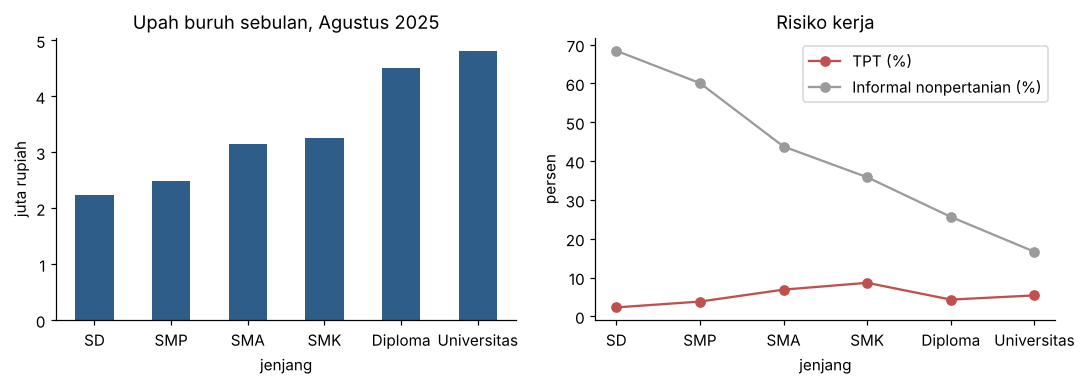

In [4]:
TAHUN = 2025
JENJANG = ["SD", "SMP", "SMA", "SMK", "Diploma", "Universitas"]
LABEL = {"Sekolah Dasar": "SD", "Sekolah Menengah Pertama": "SMP", "Sekolah Menegah Pertama": "SMP",
         "Sekolah Menengah Atas (Umum)": "SMA", "Sekolah Menengah Atas (Kejuruan)": "SMK",
         "Diploma I/II/III/Akademi": "Diploma", "Universitas": "Universitas",
         "Tidak/Belum Pernah Sekolah/Belum Tamat & Tamat SD": "SD", "<= SD": "SD", "SMP": "SMP",
         "SMA umum": "SMA", "SMA Umum": "SMA", "SMA Kejuruan": "SMK", "Diploma I/II/III": "Diploma"}

def per_tahun(df):
    df = df.assign(jenjang=df["vervar"].map(LABEL)).dropna(subset=["jenjang"])
    return df.pivot_table(index="tahun", columns="jenjang", values="nilai")[JENJANG]

tpt_tren = per_tahun(data["tpt_pendidikan"])
setengah_tren = per_tahun(data["setengah_pengangguran_pendidikan"])
informal_tren = per_tahun(data["informal_pendidikan"])
perjam_tren = per_tahun(data["upah_per_jam_pendidikan"])
upah_nas = per_tahun(data["upah_buruh_pendidikan"].query("turvar == 'Jumlah' and periode == 'Agustus'"))

status = data["status_pekerjaan_pendidikan"].query("tahun == @TAHUN and periode == 'Agustus'").copy()
status["vervar"] = status["vervar"].str.replace(r"<[^>]+>", "", regex=True).str.strip()
status = status.pivot_table(index="turvar", columns="vervar", values="nilai")
porsi_buruh = (status["Buruh/Karyawan/Pegawai"] / status["Total"] * 100).rename({"D1-D3": "Diploma", "S1 ke atas": "Universitas"})

jenjang_nas = pd.DataFrame({
    "Upah bulanan (juta Rp)": upah_nas.loc[TAHUN] / 1e6,
    "TPT (%)": tpt_tren.loc[TAHUN],
    "Setengah pengangguran (%)": setengah_tren.loc[TAHUN],
    "Informal nonpertanian (%)": informal_tren.loc[TAHUN],
    "Porsi buruh (%)": [porsi_buruh.get({"SMK": "SMA"}.get(j, j)) for j in JENJANG],
})
jenjang_nas["Pendapatan setelah risiko (juta Rp)"] = jenjang_nas["Upah bulanan (juta Rp)"] * (1 - jenjang_nas["TPT (%)"] / 100)
display(jenjang_nas)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
jenjang_nas["Upah bulanan (juta Rp)"].plot.bar(ax=ax[0], color="#2F5D8A")
ax[0].set_title("Upah buruh sebulan, Agustus 2025"); ax[0].set_ylabel("juta rupiah"); ax[0].tick_params(axis="x", rotation=0)
jenjang_nas[["TPT (%)", "Informal nonpertanian (%)"]].plot(ax=ax[1], marker="o", color=["#C0504D", "#9B9B9B"])
ax[1].set_title("Risiko kerja"); ax[1].set_ylabel("persen"); ax[1].set_xticks(range(6), JENJANG)
plt.tight_layout(); plt.show()

- Upah naik di tiap jenjang, dari 2,243 juta rupiah (SD) sampai 4,805 juta rupiah (Universitas). Upah SMK sedikit di atas SMA (3,257 lawan 3,150 juta rupiah).
- **TPT tidak turun** seiring pendidikan. TPT naik dari SD (2,300 persen) sampai SMK (8,630 persen, tertinggi), lalu turun di Diploma (4,310 persen) dan Universitas (5,390 persen).
- Kerja informal turun dari 68,430 persen (SD) ke 16,630 persen (Universitas), sedangkan porsi buruh naik dari 21,323 persen ke 76,861 persen. Upah buruh lebih mewakili lulusan jenjang tinggi daripada jenjang rendah.

### 2.2 Premi tiap jalur dan risikonya antarsektor

- Lima jalur dinilai, yaitu SMP ke SMA, SMP ke SMK, SMA ke Diploma, SMA ke Universitas, dan SMP ke Universitas.
- Premi diukur sebagai selisih logaritma pendapatan setelah risiko, kira-kira persentase tambahan pendapatan.
- Risiko premi diukur dari simpangan baku premi di 17 lapangan usaha (Agustus 2025). Imbal per risiko adalah rata-rata premi dibagi simpangan bakunya.

,Premi upah (%),Premi setelah risiko (log),Imbal per tahun sekolah,Rata-rata premi antarsektor,SD premi antarsektor,Sektor premi negatif,Imbal per risiko
Jalur,,,,,,,
SMP ke SMA,26.859,0.205,0.068,0.319,0.128,0,2.499
SMP ke SMK,31.166,0.220,0.073,0.353,0.135,0,2.610
SMA ke Diploma,42.890,0.384,0.128,0.447,0.193,0,2.316
SMA ke Universitas,52.550,0.438,0.110,0.592,0.116,0,5.107
SMP ke Universitas,93.525,0.644,0.092,0.910,0.138,0,6.598


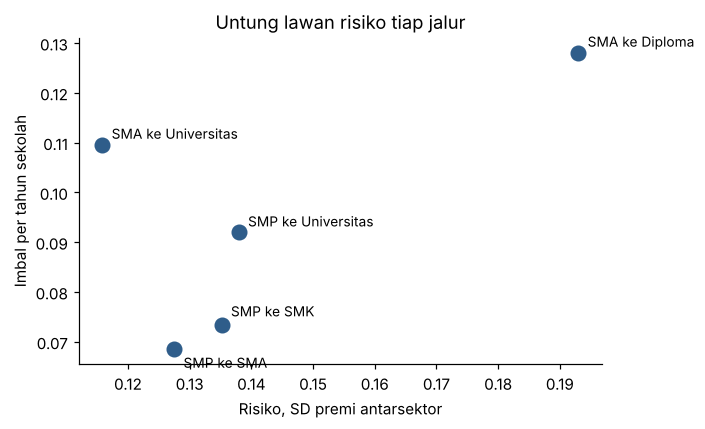

In [5]:
JALUR = {"SMP ke SMA": ("SMP", "SMA", [("SMA", 3)], 15), "SMP ke SMK": ("SMP", "SMK", [("SMA", 3)], 15),
         "SMA ke Diploma": ("SMA", "Diploma", [("PT", 3)], 18), "SMA ke Universitas": ("SMA", "Universitas", [("PT", 4)], 18),
         "SMP ke Universitas": ("SMP", "Universitas", [("SMA", 3), ("PT", 4)], 15)}

sektor = data["upah_buruh_pendidikan_sektor"].query("tahun == @TAHUN and periode == 'Agustus' and turvar != 'Total'")
sektor = sektor.assign(jenjang=sektor["vervar"].map(LABEL)).dropna(subset=["jenjang"]).pivot_table(index="turvar", columns="jenjang", values="nilai")
E_nas = jenjang_nas["Pendapatan setelah risiko (juta Rp)"]

baris = []
for jalur, (asal, tujuan, tahap, _) in JALUR.items():
    premi_sektor = np.log(sektor[tujuan] / sektor[asal]).dropna()
    baris.append({"Jalur": jalur,
                  "Premi upah (%)": (upah_nas.loc[TAHUN, tujuan] / upah_nas.loc[TAHUN, asal] - 1) * 100,
                  "Premi setelah risiko (log)": np.log(E_nas[tujuan] / E_nas[asal]),
                  "Imbal per tahun sekolah": np.log(E_nas[tujuan] / E_nas[asal]) / sum(n for _, n in tahap),
                  "Rata-rata premi antarsektor": premi_sektor.mean(),
                  "SD premi antarsektor": premi_sektor.std(),
                  "Sektor premi negatif": int((premi_sektor < 0).sum())})
premi = pd.DataFrame(baris).set_index("Jalur")
premi["Imbal per risiko"] = premi["Rata-rata premi antarsektor"] / premi["SD premi antarsektor"]
display(premi)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(premi["SD premi antarsektor"], premi["Imbal per tahun sekolah"], s=90, color="#2F5D8A")
geser = {"SMP ke SMA": (6, -12), "SMP ke SMK": (6, 6)}
for nama, r in premi.iterrows():
    ax.annotate(nama, (r["SD premi antarsektor"], r["Imbal per tahun sekolah"]), xytext=geser.get(nama, (6, 4)), textcoords="offset points", fontsize=9)
ax.set_xlabel("Risiko, SD premi antarsektor"); ax.set_ylabel("Imbal per tahun sekolah")
ax.set_title("Untung lawan risiko tiap jalur")
plt.tight_layout(); plt.show()

- Premi setelah risiko SMP ke SMA 0,205, atau 0,068 per tahun sekolah. SMA ke Diploma memberi imbal per tahun tertinggi (0,128), disusul SMA ke Universitas (0,110).
- Tidak ada lapangan usaha dengan premi negatif di kelima jalur (0 dari 17 sektor).
- **Imbal per risiko** SMA ke Universitas 5,107, lebih dari dua kali SMA ke Diploma (2,316). Premi sarjana lebih seragam antarsektor, sedangkan premi Diploma lebih bergantung sektor.

### 2.3 Arus kas dan lama balik modal

- Keputusan lanjut sekolah dibandingkan dengan langsung bekerja di jenjang asal. Selama sekolah, arus kas berisi biaya pendidikan ditambah gaji yang dilepas. Setelah lulus, arus kas berisi selisih pendapatan setelah risiko, sampai umur 59.
- Pendapatan tiap umur dikoreksi profil upah menurut kelompok umur (Agustus 2025), dengan asumsi bentuk profilnya sama untuk semua jenjang.
- Biaya per peserta didik setahun dari Statistik Penunjang Pendidikan 2024. Porsi iuran sekolah dinaikkan ke harga Agustus 2025 memakai IHK subkelompok pendidikan per provinsi, sedangkan uang saku dan transpor tetap nominal.

$$
CF_t =
\begin{cases}
-B_t - E_{asal}\,f(a_t) & t \le T_s \\
(E_{tujuan} - E_{asal})\,f(a_t) & t > T_s
\end{cases}
$$

$$
NPV(r) = \sum_{t=1}^{n} \frac{CF_t}{(1+r)^t}, \qquad NPV(IRR) = 0
$$

- $B_t$ adalah biaya pendidikan tahun ke-$t$, $T_s$ lama sekolah, $f(a_t)$ faktor upah umur, dan $r$ tingkat diskonto.
- Payback adalah tahun pertama arus kas kumulatif tanpa diskonto tidak lagi negatif, dihitung sejak mulai sekolah.

,NPV 6% (juta Rp),IRR (%),Payback (tahun),Umur balik modal,Payback terdiskonto 6% (tahun)
Jalur,,,,,
SMP ke SMA,3.878,6.333,18,32,39
SMP ke SMK,9.926,6.836,17,31,34
SMA ke Diploma,90.432,10.740,12,29,17
SMA ke Universitas,77.027,9.107,14,31,21
SMP ke Universitas,68.552,8.071,18,32,27


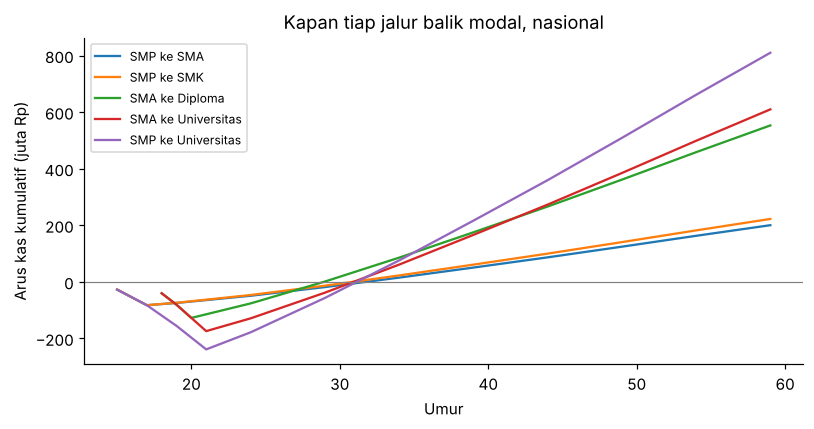

In [6]:
def kunci(nama):
    s = str(nama).upper().strip()
    s = re.sub(r"^PROV(INSI)?\s+", "", s)
    s = s.replace("KEP. ", "KEPULAUAN ").replace("D.I. ", "DI ").replace("DAERAH ISTIMEWA ", "DI ")
    return re.sub(r"[^A-Z]", "", s)

def upah_provinsi(th):
    d = data[f"upah_buruh_prov_pendidikan_ags{th}"].replace({"Diploma I/II/III": "Diploma"})
    return d[d["pendidikan"].isin(JENJANG)].pivot(index="provinsi", columns="pendidikan", values="upah_rp")[JENJANG]

def tpt_provinsi(th):
    ak = data[f"angkatan_kerja_prov_pendidikan_ags{th}"].pivot(index="provinsi", columns="pendidikan", values="orang")
    pg = data[f"penganggur_prov_pendidikan_ags{th}"].pivot(index="provinsi", columns="pendidikan", values="orang")
    t = pd.DataFrame({j: pg[k] / ak[k] * 100 for j, k in [("SD", "SD ke bawah"), ("SMP", "SMP"), ("SMA", "SMA"), ("SMK", "SMK")]})
    if "Diploma dan Universitas" in pg:  # 2025, penganggur Diploma dan Universitas digabung, dipecah memakai rasio TPT nasional
        pt = pg["Diploma dan Universitas"] / (ak["Diploma I/II/III"] + ak["DIV/S1/S2/S3"]) * 100
        t["Diploma"] = pt * tpt_tren.loc[th, "Diploma"] / pt["Indonesia"]
        t["Universitas"] = pt * tpt_tren.loc[th, "Universitas"] / pt["Indonesia"]
    else:
        t["Diploma"] = pg["Diploma I/II/III"] / ak["Diploma I/II/III"] * 100
        t["Universitas"] = pg["DIV/S1/S2/S3"] / ak["DIV/S1/S2/S3"] * 100
    return t[JENJANG]

UPAH = {th: upah_provinsi(th) for th in (2024, 2025)}
TPT = {th: tpt_provinsi(th) for th in (2024, 2025)}
PROVINSI = list(UPAH[TAHUN].index)
nama_baku = {kunci(p): p for p in PROVINSI}

biaya = data["biaya_pendidikan_prov_jenjang_2023_2024"].pivot(index="provinsi", columns="jenjang", values="biaya_juta_rp").rename(columns={"SMA/SMK": "SMA"})
komponen = data["biaya_pendidikan_komponen_persen_2023_2024"].set_index("komponen")
SAKU = {"SMA": komponen.loc["Uang Saku", "sma_smk"] / 100, "PT": komponen.loc["Uang Saku", "pt"] / 100}
TRANSPOR = {"SMA": komponen.loc["Uang Transpor", "sma_smk"] / 100, "PT": komponen.loc["Uang Transpor", "pt"] / 100}
SEKOLAH = {lv: 1 - SAKU[lv] - TRANSPOR[lv] for lv in SAKU}

ihk = data["ihk_pendidikan_provinsi"].copy()
ihk["provinsi"] = ihk["vervar"].map(lambda v: "Indonesia" if kunci(v) == "INDONESIA" else nama_baku.get(kunci(v)))
INFLASI = {}
for th in (2024, 2025):
    INFLASI[th] = pd.DataFrame({lv: (lambda d: d[(th, "Agustus")] / d[(2024, "Maret")])(
        ihk[ihk["turvar"] == sub].pivot_table(index="provinsi", columns=["tahun", "periode"], values="nilai"))
        for lv, sub in [("SMA", "Pendidikan Menengah"), ("PT", "Pendidikan Tinggi")]})

umur = data["upah_buruh_umur"].query("turvar == 'Jumlah' and periode == 'Agustus' and tahun == @TAHUN").set_index("vervar")["nilai"]
PROFIL = (umur.drop("Rata-Rata") / umur["Rata-Rata"]).to_dict()

def faktor_umur(a):
    for kel, f in PROFIL.items():
        if kel[:2].isdigit() and int(kel[:2]) <= a <= int(kel[3:5]):
            return f
    return PROFIL["55-59"]

def arus_kas(jalur, prov="Indonesia", th=TAHUN, uang_saku=True, koreksi_tpt=True, biaya_kali=1.0, tpt_tujuan_kali=1.0, saku_saja=False):
    asal, tujuan, tahap, mulai = JALUR[jalur]
    u, t = UPAH[th].loc[prov], TPT[th].loc[prov]
    e_asal = u[asal] * 12 * ((1 - t[asal] / 100) if koreksi_tpt else 1)
    e_tujuan = u[tujuan] * 12 * ((1 - t[tujuan] * tpt_tujuan_kali / 100) if koreksi_tpt else 1)
    biaya_th = []
    for lv, n in tahap:
        porsi = {"sekolah": SEKOLAH[lv] * INFLASI[th].loc[prov, lv], "saku": SAKU[lv], "transpor": TRANSPOR[lv]}
        if saku_saja:
            porsi = {"saku": SAKU[lv]}
        elif not uang_saku:
            porsi.pop("saku")
        biaya_th += [biaya.loc[prov, lv] * 1e6 * sum(porsi.values()) * biaya_kali] * n
    umur_ = np.arange(mulai, 60)
    f = np.array([faktor_umur(a) for a in umur_])
    b = np.array(biaya_th + [0.0] * (len(umur_) - len(biaya_th)))
    return umur_, np.where(np.arange(len(umur_)) < len(biaya_th), -b - e_asal * f, (e_tujuan - e_asal) * f)

def npv(arus, r):
    return float(np.sum(arus / (1 + r) ** np.arange(1, len(arus) + 1)))

def irr(arus, bawah=-0.5, atas=1.0):  # bisection, arus kas sekolah selalu negatif dulu lalu positif
    if np.isnan(arus).any() or npv(arus, bawah) * npv(arus, atas) > 0:
        return np.nan
    for _ in range(200):
        tengah = (bawah + atas) / 2
        bawah, atas = (bawah, tengah) if npv(arus, bawah) * npv(arus, tengah) <= 0 else (tengah, atas)
    return (bawah + atas) / 2

def payback(arus, r=0.0):
    kum = np.cumsum(arus / (1 + r) ** np.arange(1, len(arus) + 1))
    idx = np.where(kum >= 0)[0]
    return int(idx[0] + 1) if len(idx) else np.nan

utama = pd.DataFrame([{"Jalur": j, "NPV 6% (juta Rp)": npv(arus_kas(j)[1], 0.06) / 1e6, "IRR (%)": irr(arus_kas(j)[1]) * 100,
                       "Payback (tahun)": payback(arus_kas(j)[1]), "Umur balik modal": JALUR[j][3] + payback(arus_kas(j)[1]) - 1,
                       "Payback terdiskonto 6% (tahun)": payback(arus_kas(j)[1], 0.06)} for j in JALUR]).set_index("Jalur")
display(utama)

fig, ax = plt.subplots(figsize=(7.5, 4))
for j in JALUR:
    u_, a_ = arus_kas(j)
    ax.plot(u_, np.cumsum(a_) / 1e6, label=j)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Umur"); ax.set_ylabel("Arus kas kumulatif (juta Rp)")
ax.set_title("Kapan tiap jalur balik modal, nasional"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

- SMP ke SMA secara nasional **hanya impas tipis**, dengan NPV 3,878 juta rupiah, IRR 6,333 persen (hampir sama dengan diskonto 6 persen), dan payback 18 tahun atau umur 32.
- SMA ke Diploma memberi IRR tertinggi (10,740 persen) dan payback tercepat (12 tahun, umur 29). SMA ke Universitas memberi NPV 77,027 juta rupiah, IRR 9,107 persen, dan payback 14 tahun.
- NPV SMP ke Universitas (68,552 juta rupiah) jauh di atas SMP ke SMA (3,878 juta rupiah). Nilai SMA terutama datang dari **tiket menuju kuliah**.
- Dengan diskonto 6 persen, SMP ke SMA baru balik modal 39 tahun setelah mulai sekolah.

### 2.4 Sensitivitas terhadap asumsi

- Tiga asumsi diuji, yaitu diskonto 3, 6, dan 9 persen, biaya dengan dan tanpa uang saku, serta dengan dan tanpa risiko menganggur.
- IRR berperan sebagai diskonto impas. Jalur dengan IRR di atas biaya peluang dana keluarga layak dibiayai.

In [7]:
baris = []
for j, saku, risiko, r in product(JALUR, [True, False], [True, False], [0.03, 0.06, 0.09]):
    baris.append({"Jalur": j, "Biaya": "Penuh" if saku else "Tanpa uang saku", "Risiko menganggur": "Ya" if risiko else "Tidak",
                  "Diskonto": f"{r:.0%}", "NPV": npv(arus_kas(j, uang_saku=saku, koreksi_tpt=risiko)[1], r) / 1e6})
sensitivitas = pd.DataFrame(baris).pivot_table(index=["Biaya", "Risiko menganggur", "Diskonto"], columns="Jalur", values="NPV", sort=False)[list(JALUR)]
display(sensitivitas)
print("Skenario NPV negatif dari 12:", {j: int((sensitivitas[j] < 0).sum()) for j in JALUR})

Jalur                                       SMP ke SMA  SMP ke SMK  \
Biaya           Risiko menganggur Diskonto                           
Penuh           Ya                3%            60.763      71.581   
                                  6%             3.878       9.926   
                                  9%           -21.503     -17.738   
                Tidak             3%            89.952     117.187   
                                  6%            19.449      34.675   
                                  9%           -12.407      -2.929   
Tanpa uang saku Ya                3%            75.457      86.275   
                                  6%            17.764      23.812   
                                  9%            -8.353      -4.588   
                Tidak             3%           104.647     131.882   
                                  6%            33.335      48.561   
                                  9%             0.743      10.220   

Jalur                                       SMA ke Diploma  \
Biaya           Risiko menganggur Diskonto                   
Penuh           Ya                3%               231.251   
                                  6%                90.432   
                                  9%                22.890   
                Tidak             3%               220.575   
                                  6%                82.474   
                                  9%                16.403   
Tanpa uang saku Ya                3%               250.141   
                                  6%               108.283   
                                  9%                39.794   
                Tidak             3%               239.465   
                                  6%               100.325   
                                  9%                33.308   

Jalur                                       SMA ke Universitas  \
Biaya           Risiko menganggur Diskonto                       
Penuh           Ya                3%                   237.598   
                                  6%                    77.027   
                                  9%                     1.815   
                Tidak             3%                   241.402   
                                  6%                    76.799   
                                  9%                    -0.227   
Tanpa uang saku Ya                3%                   262.422   
                                  6%                   100.168   
                                  9%                    23.451   
                Tidak             3%                   266.226   
                                  6%                    99.939   
                                  9%                    21.409   

Jalur                                       SMP ke Universitas  
Biaya           Risiko menganggur Diskonto                      
Penuh           Ya                3%                   278.199  
                                  6%                    68.552  
                                  9%                   -20.101  
                Tidak             3%                   310.870  
                                  6%                    83.930  
                                  9%                   -12.582  
Tanpa uang saku Ya                3%                   315.610  
                                  6%                   101.867  
                                  9%                     9.755  
                Tidak             3%                   348.281  
                                  6%                   117.245  
                                  9%                    17.275

Skenario NPV negatif dari 12: {'SMP ke SMA': 3, 'SMP ke SMK': 3, 'SMA ke Diploma': 0, 'SMA ke Universitas': 1, 'SMP ke Universitas': 2}


- SMP ke SMA dan SMP ke SMK bernilai negatif di 3 dari 12 skenario, semuanya pada diskonto 9 persen.
- SMA ke Universitas hanya negatif di satu skenario (biaya penuh, tanpa risiko menganggur, diskonto 9 persen, NPV −0,227 juta rupiah), sesuai IRR-nya 9,107 persen.
- Uang saku menggeser NPV SMP ke SMA dari 3,878 ke 17,764 juta rupiah. Asumsi ini paling menentukan untuk jalur SMA.
- Risiko menganggur hampir tidak mengubah NPV kuliah (77,027 lawan 76,799 juta rupiah), karena TPT sarjana dan SMA berdekatan.

### 2.5 Perbedaan antarprovinsi

- Upah dan TPT tiap provinsi menurut pendidikan diambil langsung dari publikasi Keadaan Pekerja dan Keadaan Angkatan Kerja Agustus 2025, tanpa asumsi skala terhadap nasional.
- TPT Diploma dan Universitas 2025 per provinsi dipecah dari TPT pendidikan tinggi gabungan memakai rasio TPT nasional keduanya.
- Provinsi bertanda bintang punya jumlah penganggur jenjang terkait dengan kesalahan baku relatif 25 sampai 50 persen.

,Provinsi,NPV positif,Median NPV,Payback tercepat,Payback terlama,Tidak pernah balik modal
Jalur,,,,,,
SMP ke SMA,38,13,-19.792,9.000,37.000,6
SMP ke SMK,37,15,-16.126,9.000,40.000,9
SMA ke Diploma,37,23,19.231,9.000,42.000,2
SMA ke Universitas,37,32,50.680,10.000,21.000,1
SMP ke Universitas,37,25,23.273,14.000,28.000,0


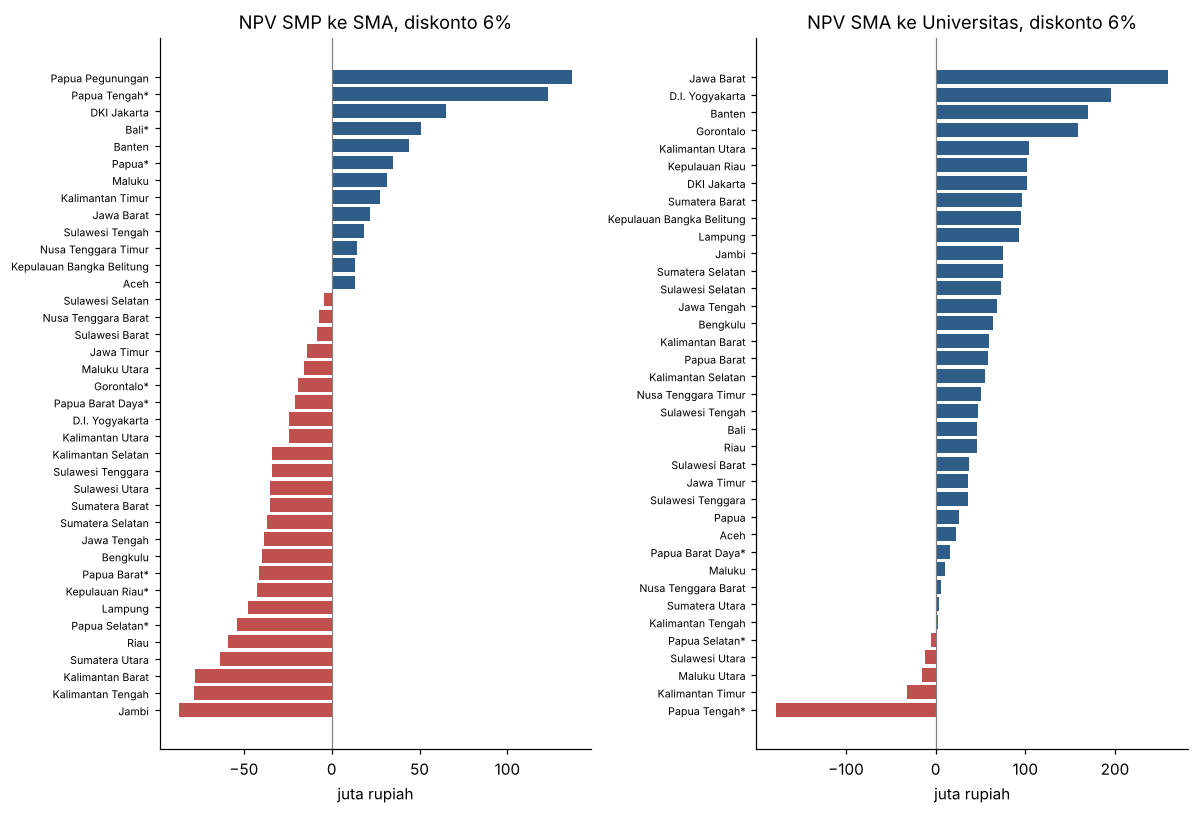

In [8]:
rse = data["penganggur_prov_pendidikan_ags2025"].query("rse_25_50 == 1")
rse = set(zip(rse["provinsi"], rse["pendidikan"]))
kolom_pg = {"SD": "SD ke bawah", "SMP": "SMP", "SMA": "SMA", "SMK": "SMK", "Diploma": "Diploma dan Universitas", "Universitas": "Diploma dan Universitas"}

def lengkap(j, p, th=TAHUN):
    asal, tujuan, tahap, _ = JALUR[j]
    ok = all(pd.notna(UPAH[th].loc[p, x]) and pd.notna(TPT[th].loc[p, x]) for x in (asal, tujuan))
    return ok and all(pd.notna(biaya.loc[p, lv]) for lv, _ in tahap)

baris = []
for p, j in product(PROVINSI, JALUR):
    if p != "Indonesia" and lengkap(j, p):
        arus = arus_kas(j, p)[1]
        asal, tujuan = JALUR[j][:2]
        tanda = "*" if (p, kolom_pg[asal]) in rse or (p, kolom_pg[tujuan]) in rse else ""
        baris.append({"Provinsi": p, "Label": p + tanda, "Jalur": j,
                      "NPV 6%": npv(arus, 0.06) / 1e6, "IRR (%)": irr(arus) * 100, "Payback": payback(arus)})
provinsi = pd.DataFrame(baris)
ringkas = provinsi.groupby("Jalur", sort=False).agg(**{
    "Provinsi": ("NPV 6%", "size"), "NPV positif": ("NPV 6%", lambda x: int((x > 0).sum())),
    "Median NPV": ("NPV 6%", "median"), "Payback tercepat": ("Payback", "min"), "Payback terlama": ("Payback", "max"),
    "Tidak pernah balik modal": ("Payback", lambda x: int(x.isna().sum()))})
display(ringkas)

fig, ax = plt.subplots(1, 2, figsize=(11, 7.5))
for k, j in enumerate(["SMP ke SMA", "SMA ke Universitas"]):
    d = provinsi[provinsi["Jalur"] == j].sort_values("NPV 6%")
    ax[k].barh(d["Label"], d["NPV 6%"], color=np.where(d["NPV 6%"] < 0, "#C0504D", "#2F5D8A"))
    ax[k].axvline(0, color="grey", lw=0.8); ax[k].set_title(f"NPV {j}, diskonto 6%"); ax[k].set_xlabel("juta rupiah")
    ax[k].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

- SMP ke SMA **positif hanya di 13 dari 38 provinsi** (median NPV −19,792 juta rupiah). Di Jambi, Kalimantan Tengah, Kalimantan Barat, Sumatera Utara, Riau, dan Lampung, SMA tidak pernah balik modal sampai umur 59.
- SMA ke Universitas positif di 32 dari 37 provinsi dengan payback 10 sampai 21 tahun. Satu-satunya yang tidak balik modal adalah Papua Tengah, yang angka penganggurnya bertanda kesalahan baku tinggi.
- NPV kuliah tertinggi ada di Jawa Barat, D.I. Yogyakarta, dan Banten, sedangkan yang negatif antara lain Kalimantan Timur, Maluku Utara, dan Sulawesi Utara, yaitu provinsi dengan upah lulusan SMA yang sudah tinggi.
- Jawa Tengah menggambarkan pola umum, yaitu SMP ke SMA negatif tetapi SMA ke Universitas positif.

### 2.6 Stabilitas hasil

- Stabilitas antarprovinsi diuji dengan korelasi peringkat Spearman antara NPV Agustus 2024 dan Agustus 2025 tiap jalur.
- $H_0$: peringkat NPV provinsi 2024 dan 2025 tidak berkorelasi ($\rho_s = 0$).
- $H_1$: peringkat NPV provinsi 2024 dan 2025 berkorelasi positif ($\rho_s > 0$).
- Taraf signifikansi 0,05, $H_0$ ditolak kalau p-value < 0,05.
- Stabilitas nasional jangka panjang dilihat dari tren premi upah per jam 2015 sampai 2024 dan TPT 2015 sampai 2025.

,Provinsi,rho Spearman,p-value,NPV nasional 2024,NPV nasional 2025,IRR nasional 2024 (%),IRR nasional 2025 (%)
Jalur,,,,,,,
SMP ke SMA,38,0.624,0.000,12.724,3.878,7.091,6.333
SMP ke SMK,37,0.720,0.000,3.961,9.926,6.349,6.836
SMA ke Diploma,35,0.701,0.000,62.506,90.432,9.442,10.740
SMA ke Universitas,37,0.874,0.000,109.189,77.027,10.304,9.107
SMP ke Universitas,37,0.806,0.000,104.401,68.552,9.096,8.071


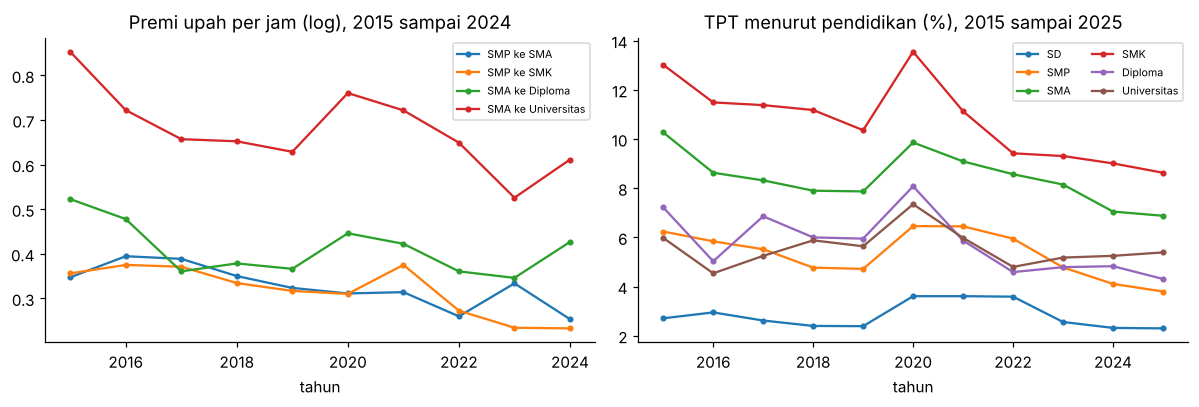

,Terendah,Tertinggi,Rata-rata
SMP ke SMA,0.254,0.395,0.328
SMP ke SMK,0.233,0.375,0.318
SMA ke Diploma,0.346,0.523,0.411
SMA ke Universitas,0.526,0.853,0.678


In [9]:
baris = []
for j in JALUR:
    pasangan = [(npv(arus_kas(j, p, 2024)[1], 0.06), npv(arus_kas(j, p, 2025)[1], 0.06)) for p in PROVINSI
                if p != "Indonesia" and lengkap(j, p, 2024) and lengkap(j, p, 2025)]
    a, b = np.array(pasangan).T / 1e6
    uji = stats.spearmanr(a, b, alternative="greater")
    baris.append({"Jalur": j, "Provinsi": len(a), "rho Spearman": uji.statistic, "p-value": uji.pvalue,
                  "NPV nasional 2024": npv(arus_kas(j, th=2024)[1], 0.06) / 1e6, "NPV nasional 2025": npv(arus_kas(j)[1], 0.06) / 1e6,
                  "IRR nasional 2024 (%)": irr(arus_kas(j, th=2024)[1]) * 100, "IRR nasional 2025 (%)": irr(arus_kas(j)[1]) * 100})
stabil = pd.DataFrame(baris).set_index("Jalur")
display(stabil)

premi_jam = pd.DataFrame({j: np.log(perjam_tren[b] / perjam_tren[a]) for j, (a, b, _, _) in JALUR.items() if j != "SMP ke Universitas"})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
premi_jam.plot(ax=ax[0], marker="o", ms=3)
ax[0].set_title("Premi upah per jam (log), 2015 sampai 2024"); ax[0].legend(fontsize=7)
tpt_tren.plot(ax=ax[1], marker="o", ms=3)
ax[1].set_title("TPT menurut pendidikan (%), 2015 sampai 2025"); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
display(premi_jam.agg(["min", "max", "mean"]).T.rename(columns={"min": "Terendah", "max": "Tertinggi", "mean": "Rata-rata"}))

- $\rho_s$ berada di rentang 0,624 sampai 0,874 dengan p-value < 0,001 di semua jalur, keputusannya **tolak $H_0$**. Peringkat provinsi stabil antara 2024 dan 2025, paling stabil di SMA ke Universitas.
- Urutan Diploma dan Universitas bergantian. IRR Universitas lebih tinggi pada 2024 (10,304 lawan 9,442 persen), sedangkan Diploma lebih tinggi pada 2025 (10,740 lawan 9,107 persen).
- IRR SMP ke SMA turun dari 7,091 persen (2024) ke 6,333 persen (2025), jadi status impas tipisnya bukan kebetulan satu tahun.
- Premi upah per jam menyusut dalam sepuluh tahun, SMA ke Universitas dari 0,853 (2015) ke 0,612 (2024) dan SMP ke SMK dari 0,356 ke 0,233. TPT SMK turun dari 13,02 ke 8,63 persen, tetapi tetap tertinggi sepanjang 2015 sampai 2025.

### 2.7 Intervensi yang paling memperpendek balik modal

- Empat intervensi disimulasikan pada skenario utama (biaya penuh, dengan risiko menganggur, diskonto 6 persen).
- Intervensi biaya dibedakan antara uang saku ditanggung (beasiswa biaya hidup) dan biaya selain uang saku ditanggung (iuran, transpor, perlengkapan).
- Intervensi pasar kerja berupa TPT lulusan jenjang tujuan turun setengah.

In [10]:
INTERVENSI = {"Tanpa intervensi": {}, "Uang saku ditanggung": {"uang_saku": False},
              "Biaya selain uang saku ditanggung": {"saku_saja": True}, "Seluruh biaya ditanggung": {"biaya_kali": 0.0},
              "TPT lulusan turun setengah": {"tpt_tujuan_kali": 0.5}}
baris = []
for nm, kw in INTERVENSI.items():
    for j in JALUR:
        arus = arus_kas(j, **kw)[1]
        baris.append({"Intervensi": nm, "Jalur": j, "NPV": npv(arus, 0.06) / 1e6, "Payback": payback(arus)})
intervensi = pd.DataFrame(baris)
display(intervensi.pivot(index="Intervensi", columns="Jalur", values="NPV").loc[list(INTERVENSI), list(JALUR)].style
        .set_caption("NPV 6% (juta Rp)").format(precision=3))
display(intervensi.pivot(index="Intervensi", columns="Jalur", values="Payback").loc[list(INTERVENSI), list(JALUR)].style
        .set_caption("Payback (tahun)").format(precision=0))

beasiswa = data["beasiswa_persen_prov_jenjang_2023_2024"].pivot(index="provinsi", columns="jenjang", values="persen_penerima")
prioritas = provinsi[provinsi["Jalur"].isin(["SMP ke SMA", "SMA ke Universitas"])].pivot(index="Provinsi", columns="Jalur", values="NPV 6%")
prioritas["Beasiswa SMA (%)"] = beasiswa.loc[prioritas.index, "SMA/SMK"]
prioritas["Beasiswa PT (%)"] = beasiswa.loc[prioritas.index, "PT"]
prioritas = prioritas[(prioritas["SMP ke SMA"] < 0) & (prioritas["Beasiswa SMA (%)"] < beasiswa.loc["Indonesia", "SMA/SMK"])]
display(prioritas.sort_values("SMP ke SMA").style.set_caption("Provinsi SMA belum balik modal dan cakupan beasiswa SMA di bawah nasional").format(precision=3))

Jalur,SMP ke SMA,SMP ke SMK,SMA ke Diploma,SMA ke Universitas,SMP ke Universitas
Intervensi,,,,,
Tanpa intervensi,3.878,9.926,90.432,77.027,68.552
Uang saku ditanggung,17.764,23.812,108.283,100.168,101.867
Biaya selain uang saku ditanggung,17.307,23.356,123.941,120.465,118.452
Seluruh biaya ditanggung,31.193,37.241,141.792,143.605,151.767
TPT lulusan turun setengah,19.307,29.944,104.829,95.289,83.885


Jalur,SMP ke SMA,SMP ke SMK,SMA ke Diploma,SMA ke Universitas,SMP ke Universitas
Intervensi,,,,,
Tanpa intervensi,18,17,12,14,18
Uang saku ditanggung,16,15,11,13,16
Biaya selain uang saku ditanggung,16,15,10,12,15
Seluruh biaya ditanggung,14,13,9,10,13
TPT lulusan turun setengah,16,15,12,14,17


Jalur,SMA ke Universitas,SMP ke SMA,Beasiswa SMA (%),Beasiswa PT (%)
Provinsi,,,,
Jambi,75.558,-86.751,15.550,11.590
Kalimantan Tengah,2.881,-78.339,5.380,nan
Kalimantan Barat,59.838,-77.831,19.050,nan
Sumatera Utara,4.139,-63.316,20.140,15.320
Riau,45.974,-59.043,18.010,12.590
Papua Selatan,-5.508,-53.986,14.290,18.570
Lampung,92.719,-47.321,22.330,23.090
Kepulauan Riau,101.977,-42.195,20.710,10.500
Sumatera Selatan,74.808,-37.019,14.000,12.270


- Untuk jalur SMA, menanggung uang saku (NPV 17,764 juta rupiah) dan menurunkan TPT lulusan setengahnya (19,307 juta rupiah) sama kuatnya, keduanya mempercepat payback 2 tahun.
- Untuk kuliah, **biaya iuran** adalah pengungkit terbesar. Menanggung biaya selain uang saku menaikkan NPV SMA ke Universitas dari 77,027 ke 120,465 juta rupiah, sedangkan menurunkan TPT setengahnya hanya ke 95,289 juta rupiah.
- Ada 15 provinsi dengan SMA belum balik modal sekaligus cakupan beasiswa SMA di bawah nasional (22,59 persen), dipimpin Jambi, Kalimantan Tengah, dan Kalimantan Barat.

## 3. Kesimpulan

- Kuliah tetap investasi yang jelas menguntungkan, dengan IRR 9,107 persen (Universitas) dan 10,740 persen (Diploma) serta NPV positif di 32 dari 37 provinsi untuk jalur sarjana.
- SMA saja hanya impas tipis secara nasional dan **belum balik modal di 25 dari 38 provinsi**. Nilainya terletak pada akses menuju kuliah dan pekerjaan formal.
- SMK tidak lebih aman dari SMA, karena TPT-nya tertinggi di semua jenjang sepanjang 2015 sampai 2025.
- Intervensi paling efektif berbeda per jenjang, yaitu beasiswa biaya hidup dan penyerapan kerja untuk SMA, serta keringanan iuran untuk kuliah.

## 4. Glosarium

Kolom pertama memakai kata yang tampil di dashboard, kolom kedua istilah teknis yang dipakai di notebook ini. Penjelasan singkatnya juga muncul di ikon ? tiap visual dashboard.

### 4.1 Istilah keuangan

| Di dashboard | Istilah teknis | Arti |
|---|---|---|
| Untung bersih | NPV (*net present value*) | Tambahan penghasilan seumur kerja dari lanjut sekolah, dikurangi biaya sekolah dan gaji yang tidak didapat selama sekolah, semuanya dalam nilai uang hari ini. Rumusnya $NPV = \sum_{t=1}^{T} CF_t/(1+r)^t$. Nilai positif berarti lanjut sekolah lebih untung daripada langsung bekerja lalu menabung dengan bunga pembanding |
| Rugi | NPV < 0 | Lanjut sekolah kalah dari langsung bekerja pada bunga pembanding yang dipilih |
| Untung tipis | 0 ≤ NPV < 10 juta rupiah | Batas yang dipakai dashboard untuk warna pink muda dan kata untung tipis |
| Imbal per tahun | IRR (*internal rate of return*) | Bunga per tahun yang dihasilkan sekolah bila diperlakukan seperti tabungan, yaitu nilai $r$ yang membuat NPV sama dengan nol. Sekolah lebih untung daripada menabung bila IRR di atas bunga pembanding |
| Bunga pembanding | Tingkat diskonto $r$ | Imbal hasil yang bisa didapat kalau uangnya ditabung. Asumsi dasar 6%, dan slicer Bunga menggesernya dari 0% sampai 12% |
| Nilai uang hari ini | Nilai sekarang (PV) | Uang yang baru diterima $t$ tahun lagi dibagi $(1+r)^t$, supaya bisa dijumlahkan dengan uang yang keluar hari ini |
| Modal yang dikeluarkan | Biaya investasi pendidikan | Biaya sekolah ditambah gaji yang tidak didapat selama sekolah, dalam PV |
| Gaji yang tidak didapat, gaji tak didapat | *Opportunity cost* atau *foregone earnings* | Gaji yang hilang karena memilih sekolah daripada bekerja, dihitung dari upah jenjang asal dikali peluang bekerja dan faktor umur |
| Modal kembali dalam (tanpa bunga) | *Payback period* | Tahun pertama sejak mulai sekolah saat arus kas kumulatif tidak lagi negatif |
| Modal kembali dengan bunga | *Discounted payback period* | Sama dengan di atas, tetapi arus kasnya didiskonto dulu, sehingga selalu lebih lama |
| Perjalanan modal, saldo untung rugi | Arus kas kumulatif | Jumlah berjalan arus kas tahunan dari umur mulai sekolah sampai umur 59. Titik saat garis memotong nol adalah umur modal kembali, dan ujung garisnya sama dengan NPV |
| Selisih gaji | Premi upah | Selisih upah jenjang tujuan terhadap jenjang asal, dalam log $\ln(w_b/w_a)$ atau persen |
| Pilihan sekolah | Jalur pendidikan | Lima keputusan lanjut sekolah, yaitu SMP ke SMA, SMP ke SMK, SMA ke Diploma, SMA ke Universitas, dan SMP ke Universitas (lanjut SMA lalu kuliah, 7 tahun) |
| Pilihan paling untung | Jalur dengan NPV tertinggi | Jalur dengan NPV terbesar pada asumsi dasar di provinsi dan tahun yang dipilih |

### 4.2 Istilah pendidikan dan pasar kerja

| Di dashboard | Istilah teknis | Arti |
|---|---|---|
| Risiko menganggur, persen menganggur | Tingkat Pengangguran Terbuka (TPT) | Persen angkatan kerja yang tidak bekerja dan sedang mencari kerja atau menyiapkan usaha, menurut definisi BPS |
| Gaji sebulan | Upah atau gaji bersih sebulan buruh | Upah buruh, karyawan, dan pegawai menurut pendidikan tertinggi yang ditamatkan (Sakernas Agustus). Pendapatan berusaha sendiri tidak termasuk |
| Bekerja informal | Pekerja informal nonpertanian | Pekerja di luar sektor pertanian yang berusaha sendiri, berusaha dibantu buruh tidak tetap, pekerja bebas, atau pekerja keluarga, sehingga umumnya tanpa kontrak dan jaminan kerja |
| Ijazah terakhir, jenjang | Pendidikan tertinggi yang ditamatkan | SD mencakup yang tidak atau belum pernah sekolah dan belum tamat SD. Diploma adalah D1 sampai D3, Universitas adalah D4, S1, S2, dan S3 |
| Uang saku | Komponen biaya pendidikan | Uang saku siswa sebagai bagian biaya pendidikan Susenas MSBP 2024, yaitu 50,98% biaya SMA dan 35,13% biaya perguruan tinggi. Slicer Uang saku menentukan komponen ini ikut dihitung atau tidak |
| Dapat beasiswa | Persentase penerima beasiswa | Persen siswa SMA dan SMK penerima beasiswa per provinsi, tahun ajaran 2023/2024 (Statistik Penunjang Pendidikan 2024) |
| Data kurang akurat (*) | RSE 25% sampai 50% | Jumlah penganggur provinsi menurut pendidikan yang ditandai BPS punya *relative standard error* 25% sampai 50%, sehingga angkanya perlu dibaca hati-hati |
| Tahun data | Sakernas Agustus 2024 dan 2025 | Dua gelombang Survei Angkatan Kerja Nasional yang punya upah dan TPT provinsi menurut pendidikan |
| Selisih SMK dikurangi SMA (poin) | Selisih TPT dalam poin persen | TPT lulusan SMK dikurangi TPT lulusan SMA pada tahun yang sama, data nasional 2015 sampai 2025 |

### 4.3 Simulasi bantuan

| Di dashboard | Cara simulasinya | Arti |
|---|---|---|
| Bantuan uang saku | Komponen uang saku dihapus dari biaya | Negara menanggung uang saku siswa selama sekolah |
| Bantuan iuran dan ongkos sekolah | Biaya tinggal uang saku | Iuran sekolah dan ongkos transportasi ditanggung, uang saku tetap dibayar keluarga |
| Sekolah gratis penuh | Seluruh biaya bernilai nol | Batas atas dampak bantuan biaya, dipakai sebagai pembanding dan bukan usulan |
| Pengangguran lulusan turun setengahnya | TPT jenjang tujuan dikali 0,5 | Peluang lulusan mendapat kerja membaik, misalnya lewat kerja sama sekolah dengan industri |

### 4.4 Istilah dashboard dan asumsi

| Di dashboard | Arti |
|---|---|
| Asumsi dasar | Bunga pembanding 6%, uang saku dihitung, risiko menganggur dihitung, bekerja sampai umur 59, dan bentuk profil upah menurut umur Agustus 2025 untuk kedua tahun data |
| Slicer | Pilihan di bagian atas halaman, yaitu provinsi, tahun data, pilihan sekolah, bunga, uang saku, dan risiko menganggur. Pilihan provinsi dan tahun ikut terbawa saat pindah halaman |
| Nasional | Baris Indonesia, bukan rata-rata provinsi |
| Warna kuning | Provinsi, pilihan sekolah, atau tahun yang sedang dipilih |
| Ungu tua, pink muda, pink tua | NPV di bawah nol, 0 sampai 10 juta rupiah, dan di atas 10 juta rupiah |
| Faktor umur | Upah kelompok umur dibagi upah rata-rata (Sakernas Agustus 2025), dipakai supaya gaji tidak dianggap sama dari umur 15 sampai 59 |
| Penyesuaian harga biaya sekolah | Biaya 2023/2024 dinaikkan memakai IHK subkelompok pendidikan provinsi sampai Agustus tahun data. Hanya komponen iuran yang disesuaikan, uang saku dan transportasi tidak |